# 5장 1강: 배깅과 랜덤포레스트

## 실습 목표
이번 실습에서는 **Ames Housing** 데이터를 이용하여 배깅과 랜덤포레스트의 핵심 원리를 확인합니다.

- 하나의 의사결정나무와 여러 나무를 모은 배깅의 차이를 확인합니다.
- 배깅에서 여러 회귀 모델의 예측을 평균내는 이유를 이해합니다.
- 랜덤포레스트의 부트스트랩과 피처 무작위 선택 개념을 확인합니다.
- OOB Score와 Feature Importance를 확인합니다.
- 여러 나무를 평균낼 때 분산이 줄어드는 이유를 설명합니다.

> 교안에 나온 범위만 사용합니다.

## 실습 환경 / 데이터
- Python, pandas, numpy, matplotlib, scikit-learn
- 데이터: `Ames_Housing.csv`
- 예측 대상: `SalePrice`

사용 특성:
`OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`,
`2ndFlrSF`, `FullBath`, `TotRmsAbvGrd`, `YearBuilt`, `YearRemodAdd`, `Fireplaces`

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.metrics import r2_score

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual","GrLivArea","GarageCars","GarageArea",
    "TotalBsmtSF","1stFlrSF","2ndFlrSF","FullBath",
    "TotRmsAbvGrd","YearBuilt","YearRemodAdd","Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
display(X.isna().sum().to_frame("missing"))

Train: (1168, 12)
Test: (292, 12)


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
GarageArea,0
TotalBsmtSF,0
1stFlrSF,0
2ndFlrSF,0
FullBath,0
TotRmsAbvGrd,0
YearBuilt,0


# 필수 1. 하나의 나무와 Bagging 비교

## 문제 1. Decision Tree 하나를 학습하세요.
1. `DecisionTreeRegressor(random_state=42)` 사용
2. Train 학습
3. Train/Test 예측
4. Train R², Test R² 계산
5. 두 점수 차이 해석

In [3]:
# TODO
# Decision Tree 모델 생성
tree = DecisionTreeRegressor(random_state=42)

# Train 데이터로 학습
tree.fit(X_train, y_train)

# Train / Test 예측
train_pred = tree.predict(X_train)
test_pred = tree.predict(X_test)

# Train / Test R² 계산
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

print("Train R²:", train_r2)
print("Test R²:", test_r2)
print("R² 차이:", train_r2 - test_r2)

Train R²: 0.9999007920351307
Test R²: 0.7938734688847873
R² 차이: 0.20602732315034344


tree = DecisionTreeRegressor(random_state=42) : 깊이를 제한하지 않은 회귀나무
-> max_depth 를 지정하지 않았기 때문에 무한하게 학습을 할 수도 있겠다라고 판단할 수 있지만
더 나눌 수 없거나 기본 분할 조건을 만족하지 못하면 멈춘다. 

결과 
Train 이 1에 가깝다는 것의 의미 
->일반적으러 R2가 1에 가깝다는 것은 모델이 충분히 해당 데이터에 대한 설명력을 가지고 있다는 것이지만
->지나치게 성능이 높은 경우 과적합 위험을 의심하여 추가적인 검증이 필요하다. 

# Q1. Train R²는 매우 높은데 Test R²가 더 낮다면 무엇을 의미하나요?

**답변:(정답) 이는 하나의 나무가 학습 데이터 변화에 민감한 분산이 큰 모델임을 보여준다. 
Decision Tree의 한 그루는 불안정할 수 있다.

나의 답변: 과적합이 되었을 가능성이 있다. 학습 데이터에서는 1에 가깝게 나왔지만 시험 데이터에서 0.2만큼 낮게 나왔으므로 학습데이터에서 설명력 만큼
시험 데이터에서 설명력이 나오지 않았다. 

## 문제 2. Bagging을 적용하세요.
1. 기본 모델은 `DecisionTreeRegressor(random_state=42)`
2. `BaggingRegressor`
3. `n_estimators=50`
4. `random_state=42`
5. Test R² 계산
6. `max_features="sqrt`
7. Decision Tree 하나와 비교

In [4]:
# TODO
# Bagging의 기본 모델
base_tree = DecisionTreeRegressor(
    max_features="sqrt",
    random_state=42
)

# Bagging 모델
bagging = BaggingRegressor(
    estimator=base_tree,
    n_estimators=50,
    random_state=42
)

# Train 데이터로 학습
bagging.fit(X_train, y_train)

# Test 데이터 예측
bagging_pred = bagging.predict(X_test)

# Test R² 계산
bagging_test_r2 = r2_score(y_test, bagging_pred)

# Decision Tree 하나와 Bagging 비교
print("Decision Tree Test R²:", test_r2)
print("Bagging Test R²:", bagging_test_r2)

Decision Tree Test R²: 0.7938734688847873
Bagging Test R²: 0.8914475757000427


배깅,  나무 50개를 평균한다는 것의 의미. 
어떤 트리가 특정 주택을 높게 예측하고 다른 트리가 낮게 예측하면 평균에서 오류가 일부 상쇄될 수 있다.
다만, 여러 트리가 모두 같은 방향으로 크게 틀리는 경우 평균을 해도 오류가 남는다. 
따라서 무조건 모델 수만 늘리면 오류를 해결할 수 있는 것은 아니다. 

## Q2. 왜 각 나무를 서로 다른 부트스트랩 샘플로 학습하나요?

**답변:** : 서로 다른 부트스트랩 샘플로 학습하는 것은 각 나무 별 학습 할 데이터를 다르게 한다는 것.
완전히 같은 데이터로 여러 나무를 구성하게 되면 모델이 비슷한 학습을 보이기 때문에 앙상블 효과가 적어짐.
부트스트랩으로 학습 데이터셋을 조금씩 바꾸면 나무마다 다른 오류 패턴을 학습하고 평균을 내는 과정에서 오류가 일부 상쇄될 가능성이 있음. 

# 필수 2. Random Forest의 OOB Score와 Feature Importance

## 문제 1. OOB Score를 확인하세요.
1. `RandomForestRegressor`
2. `n_estimators=100`
3. `bootstrap=True`
4. `oob_score=True`
5. `random_state=42`
6. Test R²와 `oob_score_` 출력

In [5]:
# TODO

각 Train 표본의 OOB 예측을 따로 모은다.
->어떤 Train 주택 A를 예측할 때 A를 한번도 뽑지 않은 나무들만 사용한다.
1, 4, 7번 나무가 A를 학습하지 않았다면 A예측 평균을 사용한다. 

Test R2 은 0.89 <- 별도 100개의 나무 전체의 평균
OOB Score <--각 train 표본을 학습하지 않은 나무들의 표본 예측 결과. 

# Out-of-Bag (OOB) 계산식

$$P(\text{OOB}) = \left(1 - \frac{1}{N}\right)^N \approx e^{-1} \approx 0.368$$

*OOB 0.81  이라는 것의 의미.*
-> 예측 제곱 오차의 합이 트레인보다 83%보다 작다. 
-> OOB 예측의 제곱오차 합이 Train 실제 평균 가격을 예측하는 기준보다 83% 정도 작다. 
-> OOB 지표도 음수가 될 수 있다. 

*별도 검증이나 교차 검증을 대체할 수 있는가?*
OOB는 부트스트랩 학습의 남은 데이터셋을 이용하니까 Train / Vaildation 분할 없이 모델을 점검하는 데 편리
목적에 맞는 데이터 셋과 설계에 따라 검증이나 교차검증이 추가적으로 필요한 경우들이 있다.
독립적인 결과를 해석하는 경우는 적다.

# Q3. OOB 샘플은 무엇인가요?

*답변:  샘플은 부트스트랩 샘플링에서 한 번도 선택되지 않은 데이터.
->한번도 학습에 사용되지 않았던 데이터들을 모은 것. 
# Q4. OOB Score가 교차검증을 완전히 대체하나요?

*답변: 완전히 대체하지는 않는다. OOB는 편리한 추정치를 산출하지만 데이터가 적은 상황, 신뢰도가 더 높게 필요한 상황이라면 교차검증과 함께 쓰는 것이 일반적이다. 
->완전하게 대체는 불가능하다. 모델에 대해서 빠르고 편리하게 추정치를 얻을 수 있지만 교차검증을 완전히 대체할 수는 없다. 

## 문제 2. Feature Importance를 확인하세요. 
--->직관적이고 설명하기 편하다. 코드 해석하는 부분에 있어 중요. --발표할 때 오래동안 설명하는 부분이다. 
1. `feature_importances_` 사용
2. 특성명과 중요도 DataFrame 생성
3. 내림차순 정렬
4. 막대그래프
5. 가장 높은 중요도 특성 확인

-->그래프를 해석할 수 있으면 된다. 

In [6]:
# TODO

그래프 해석: 
모델링할 때 낮았던 피쳐들도 쓸 수 있다. -->피쳐를 선택하는 근거. 피쳐 importance 결과로 어떤 얼마만큼 정도의 설명력을 가진다고 설명할 수 있어야 한다.

OverallQual 의 막대가 0.23까지 나타나있고, GrLivArea 가 0.17 이라는 것은 품질과 지상 면적에 약 40%정도의 설명력을 갖기고 있다는 것으로 해석할 수 있음. 
이 두 가지 지표로 전체 중요도의 40%정도 이기 때문에 가격변동(Y)의 40%는 중요한 참고 데이터로 사용함.
단 R2 이 40%정도다 라고 설명하는 것은 적절하지 않음. 

*중요도 0.23을 어떻게 해석할 수 있는가?*
:가장 정확한 정의는 랜덤 포레스트의 불순도(지니계수) 기반 중요도에서 OverallQual(품질)이 약 23%정도 차지 했다. 

*잘못된 해석*
품질이 집값의 23%를 결정한다.--> 품질 1등급 올리면 가격이 23%상승한다. 
=>높았던 feature들이 중요하다. 낮았던 feature들도 필요하다. 
낮은 중요도는 쓸모없는 변수라는 것을 의미하는가?
->아님, 해당 모델이 예측할 때 조금 덜 힌트를 얻었다는 식으로 설명할 수 있음. 

*중요도 해석 한계점*
: 불순도 기반 중요도가 가능한 분할 지점이 많은 특성에 유리하게 작용.
: 따라서 상관된 특성끼리 중요도가 나뉘거나 쏠리는 현상이 있을 수 있음.

중요도 점수에 따라 이 변수에 따라서 어느 정도의 영향이 있는지 확인(해석)할 수 있다. 
->현재 이 모델에서 중요도는 품질 등급과 지상 면적이 가장 크다. 이 부분은 이 입력 구성과 학습 설정에서 모델이 예측을 위해 사용한 분할 정보의 기여를 의미한다. 


# Q5. Feature Importance가 높다는 것이 그 변수가 주택가격의 원인이라는 뜻인가요?

**답변:** 모델이 예측할 때 해당 변수를 많이 참고했다는 뜻. 
아님, 중요도가 높다 라는 것의 올바른 해석은 현재 모델이(설정상태) 예측을 할 때 많이 활용했다는 의미.

# 과제 1. 나무 수와 예측 안정성 확인

`tree_counts = [1, 10, 50, 100]`을 사용하세요.

각 나무 수에서:
1. RandomForestRegressor 생성
2. `bootstrap=True`, `random_state=42`
3. Train 학습
4. Test R² 계산
5. DataFrame 정리
6. 나무 수에 따른 성능 변화 확인
7. 여러 예측의 평균과 분산 감소 관계 설명

,n_trees,test_r2
0,1,0.742870
1,10,0.883597
2,50,0.889467
3,100,0.890075


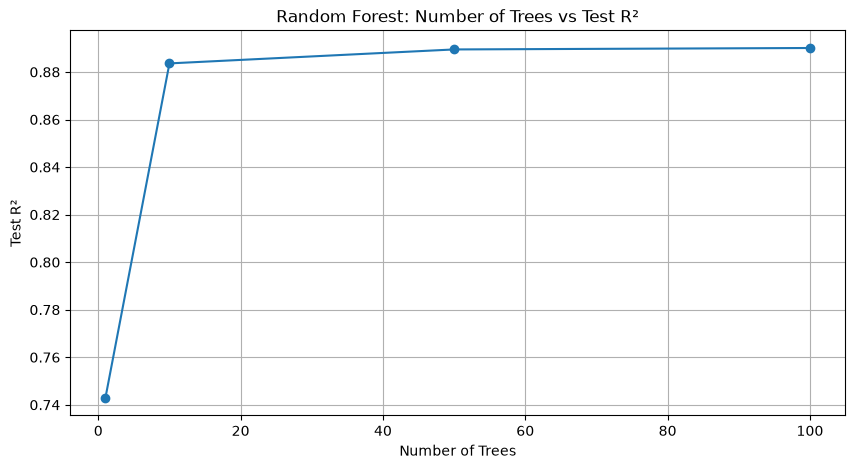

In [7]:
# TODO 1. 나무 수 설정
tree_counts = [1, 10, 50, 100]

results = []

# TODO 2. 나무 수별 RandomForest 모델 학습 및 평가
for n in tree_counts:
    rf_model = RandomForestRegressor(
        n_estimators=n,
        bootstrap=True,
        random_state=42
    )

    # Train 데이터 학습
    rf_model.fit(X_train, y_train)

    # Test 데이터 예측
    y_pred = rf_model.predict(X_test)

    # Test R² 계산
    test_r2 = r2_score(y_test, y_pred)

    results.append({
        "n_trees": n,
        "test_r2": test_r2
    })

# TODO 3. DataFrame 생성 및 출력
result_df = pd.DataFrame(results)
display(result_df)

# TODO 4. 나무 수에 따른 Test R² 변화 시각화
plt.figure(figsize=(10, 5))
plt.plot(result_df["n_trees"], result_df["test_r2"], marker="o")

plt.xlabel("Number of Trees")
plt.ylabel("Test R²")
plt.title("Random Forest: Number of Trees vs Test R²")
plt.grid(True)
plt.show()

### Q6. 나무 수를 늘리면 왜 예측이 더 안정적으로 변하나요?

**답변:** 
나무 수가 증가하면서 여러 나무의 예측을 평균하므로 안정적으로 변할 수 있다. 
### Q7. 나무 수를 계속 늘리면 분산이 무한히 0으로 줄어드나요?

**답변:** 
아니다. 나무 수가 50개 이상 100개 로 증가했을 때부터는 분산이 거의 감소하지 않는다. 나무들이 완전히 독립적인 것은 아닌 서로 상관관계가 있기 때문에. 

# 실습 마무리
1. 부트스트랩 샘플링은 어떤 방식인가요? ->중복을 허용해서 샘플링 한다.
: 원본 데이터셋에서 중복을 허용하여 같은 크기의 샘플을 추출.

2. Bagging 회귀에서는 여러 모델의 예측을 어떻게 합치나요?
: 여러 모델의 예측값의 평균

3. Random Forest가 Bagging에 추가하는 무작위성은 무엇인가요?
: 각 트리 분할에서 일부 피처만 무작위 후보로 사용. 

4. OOB 샘플은 평균적으로 약 몇 %인가요?
:37% 

5. Feature Importance가 높다는 것은 무엇을 의미하나요?  ->그 모델이 얼마나 이 변수에 대해 힌트를 얻었는가?
: 모델이 예측에 얼마나 많이 활용했는지. 

6. Bagging이 Decision Tree와 특히 잘 맞는 이유는 무엇인가요?
: Decision Tree 는 기본적으로 분산이 큰 모델인데 배깅의 분산 감소 효과와 잘 맞음. 